In [3]:
# ============================================================
# 04.01 BASELINE CROSS-MODAL EVALUATION
# Cell 1: Environment and Imports
# ============================================================

import sys
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("========== EVALUATION ENVIRONMENT ==========\n")

print("Python version :", sys.version)
print("PyTorch version:", torch.__version__)
print("NumPy version  :", np.__version__)
print("CUDA available :", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device         :", device)

print("\nEvaluation environment: READY")

========== EVALUATION ENVIRONMENT ==========

Python version : 3.14.4 (tags/v3.14.4:23116f9, Apr  7 2026, 14:10:54) [MSC v.1944 64 bit (AMD64)]
PyTorch version: 2.13.0+cpu
NumPy version  : 2.5.2
CUDA available : False
Device         : cpu

Evaluation environment: READY


In [4]:
# ============================================================
# 04.01 BASELINE CROSS-MODAL EVALUATION
# Cell 2: Project Paths
# ============================================================

# ------------------------------------------------------------
# Find project root automatically
# ------------------------------------------------------------

current_path = Path.cwd().resolve()

project_root = None

for candidate in [current_path] + list(current_path.parents):

    if (
        (candidate / "06_cross_modal_learning").exists()
        and
        (
            candidate
            / "06_cross_modal_learning"
            / "03_cross_modal_learning"
        ).exists()
    ):
        project_root = candidate
        break

if project_root is None:
    raise FileNotFoundError(
        "Could not locate project root containing "
        "'06_cross_modal_learning/03_cross_modal_learning'."
    )

# ------------------------------------------------------------
# Main Phase 3 root
# ------------------------------------------------------------

phase_root = (
    project_root
    / "06_cross_modal_learning"
)

official_phase3_root = (
    phase_root
    / "03_cross_modal_learning"
)

# ------------------------------------------------------------
# 04.01 evaluation root
# ------------------------------------------------------------

evaluation_root = (
    phase_root
    / "04_cross_modal_evaluation"
)

evaluation_01_root = (
    evaluation_root
    / "04_01_baseline_cross_modal_evaluation"
)

reports_dir = evaluation_01_root / "reports"
figures_dir = evaluation_01_root / "figures"

reports_dir.mkdir(
    parents=True,
    exist_ok=True
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Official baseline checkpoint
# ------------------------------------------------------------

baseline_checkpoint_path = (
    official_phase3_root
    / "03_04_baseline_training"
    / "checkpoints"
    / "03_04_baseline_best_model.pt"
)

# ------------------------------------------------------------
# Official Phase 02.08 validation data
# ------------------------------------------------------------

pair_dir = (
    phase_root
    / "02_cross_modal_pairing"
    / "pairs"
    / "representation_aware_split"
)

validation_npz_path = (
    pair_dir
    / "02_08_validation_representation_disjoint_pairs.npz"
)

validation_metadata_path = (
    pair_dir
    / "02_08_validation_representation_disjoint_metadata.csv"
)

# ------------------------------------------------------------
# Verify important paths
# ------------------------------------------------------------

assert project_root.exists()
assert official_phase3_root.exists()
assert evaluation_01_root.exists()

assert baseline_checkpoint_path.exists()
assert validation_npz_path.exists()
assert validation_metadata_path.exists()

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("========== PROJECT PATHS ==========\n")

print("Project root:")
print(project_root)

print("\nOfficial Phase 3 root:")
print(official_phase3_root)

print("\n04.01 evaluation root:")
print(evaluation_01_root)

print("\nBaseline checkpoint:")
print(baseline_checkpoint_path)

print("\nValidation dataset:")
print(validation_npz_path)

print("\nValidation metadata:")
print(validation_metadata_path)

print("\nReports:")
print(reports_dir)

print("\nFigures:")
print(figures_dir)

print("\nPath verification: PASSED")

========== PROJECT PATHS ==========

Project root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening

Official Phase 3 root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\03_cross_modal_learning

04.01 evaluation root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\04_01_baseline_cross_modal_evaluation

Baseline checkpoint:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\03_cross_modal_learning\03_04_baseline_training\checkpoints\03_04_baseline_best_model.pt

Validation dataset:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\02_cross_modal_pairing\pairs\representation_aware_split\02_08_validation_representation_disjoint_pairs.npz

Validation metadata:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\02_cross_mod

In [5]:
# ============================================================
# 04.01 BASELINE CROSS-MODAL EVALUATION
# Cell 3: Load Validation Dataset and Metadata
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# Load validation NPZ
# ------------------------------------------------------------

validation_data = np.load(
    validation_npz_path
)

X_val_source = validation_data[
    "source_embeddings"
].astype(np.float32)

X_val_target = validation_data[
    "target_embeddings"
].astype(np.float32)

y_val = validation_data[
    "pair_labels"
].astype(np.float32)

# ------------------------------------------------------------
# Load validation metadata
# ------------------------------------------------------------

validation_metadata = pd.read_csv(
    validation_metadata_path
)

# ------------------------------------------------------------
# Display shapes
# ------------------------------------------------------------

print("========== VALIDATION DATASET ==========\n")

print(
    "Source embeddings :",
    X_val_source.shape
)

print(
    "Target embeddings :",
    X_val_target.shape
)

print(
    "Pair labels       :",
    y_val.shape
)

print(
    "Metadata shape    :",
    validation_metadata.shape
)

# ------------------------------------------------------------
# Class distribution
# ------------------------------------------------------------

class_0_count = int(
    np.sum(y_val == 0)
)

class_1_count = int(
    np.sum(y_val == 1)
)

print("\nValidation labels:")
print("  Class 0:", class_0_count)
print("  Class 1:", class_1_count)

# ------------------------------------------------------------
# Basic integrity checks
# ------------------------------------------------------------

assert X_val_source.shape == (448, 32)
assert X_val_target.shape == (448, 32)
assert y_val.shape == (448,)

assert class_0_count == 224
assert class_1_count == 224

assert np.isfinite(X_val_source).all()
assert np.isfinite(X_val_target).all()
assert np.isfinite(y_val).all()

assert set(
    np.unique(y_val)
).issubset({0.0, 1.0})

assert len(validation_metadata) == 448

print("\nNaN / Inf check: PASSED")
print("Shape check: PASSED")
print("Class balance check: PASSED")
print("Metadata alignment check: PASSED")

print("\nValidation dataset loading: PASSED")

========== VALIDATION DATASET ==========

Source embeddings : (448, 32)
Target embeddings : (448, 32)
Pair labels       : (448,)
Metadata shape    : (448, 8)

Validation labels:
  Class 0: 224
  Class 1: 224

NaN / Inf check: PASSED
Shape check: PASSED
Class balance check: PASSED
Metadata alignment check: PASSED

Validation dataset loading: PASSED


In [6]:
# ============================================================
# 04.01 BASELINE CROSS-MODAL EVALUATION
# Cell 4: Load Official Baseline Model
# ============================================================

class BaselineCrossModalModel(nn.Module):
    """
    Official cross-modal baseline model.

    Input:
        Source embedding: 32-D
        Target embedding: 32-D

    Interaction representation:
        [S, T, |S-T|, S*T] -> 128-D

    Architecture:
        128 -> 128 -> 64 -> 1
    """

    def __init__(self, embedding_dim=32):

        super().__init__()

        interaction_dim = embedding_dim * 4

        self.classifier = nn.Sequential(

            nn.Linear(
                interaction_dim,
                128
            ),

            nn.ReLU(),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU(),

            nn.Linear(
                64,
                1
            )
        )

    def forward(
        self,
        source,
        target
    ):

        absolute_difference = torch.abs(
            source - target
        )

        elementwise_product = (
            source * target
        )

        combined = torch.cat(
            [
                source,
                target,
                absolute_difference,
                elementwise_product
            ],
            dim=1
        )

        logits = self.classifier(
            combined
        )

        return logits.squeeze(1)


# ------------------------------------------------------------
# Load official checkpoint
# ------------------------------------------------------------

baseline_checkpoint = torch.load(
    baseline_checkpoint_path,
    map_location=device,
    weights_only=False
)

# ------------------------------------------------------------
# Create model
# ------------------------------------------------------------

baseline_model = BaselineCrossModalModel(
    embedding_dim=32
).to(device)

# ------------------------------------------------------------
# Load official weights
# ------------------------------------------------------------

baseline_model.load_state_dict(
    baseline_checkpoint[
        "model_state_dict"
    ],
    strict=True
)

# ------------------------------------------------------------
# Evaluation mode
# ------------------------------------------------------------

baseline_model.eval()

# ------------------------------------------------------------
# Freeze parameters
# ------------------------------------------------------------

for parameter in baseline_model.parameters():
    parameter.requires_grad = False

# ------------------------------------------------------------
# Parameter count
# ------------------------------------------------------------

total_parameters = sum(
    parameter.numel()
    for parameter in baseline_model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in baseline_model.parameters()
    if parameter.requires_grad
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("========== OFFICIAL BASELINE MODEL ==========\n")

print(baseline_model)

print("\nTotal parameters    :", total_parameters)
print("Trainable parameters:", trainable_parameters)

print("\nCheckpoint epoch:",
      baseline_checkpoint["epoch"])

print(
    "Checkpoint best ROC-AUC:",
    baseline_checkpoint["best_val_roc_auc"]
)

print("\nModel mode:",
      "eval" if not baseline_model.training
      else "train")

print("\nCheckpoint:")
print(baseline_checkpoint_path)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

assert total_parameters == 24833
assert trainable_parameters == 0
assert not baseline_model.training

assert (
    baseline_checkpoint["best_val_roc_auc"]
    == 0.6626674107142857
)

print("\nParameter count verification: PASSED")
print("Checkpoint verification: PASSED")
print("Evaluation mode verification: PASSED")
print("Baseline model loading: PASSED")

========== OFFICIAL BASELINE MODEL ==========

BaselineCrossModalModel(
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)

Total parameters    : 24833
Trainable parameters: 0

Checkpoint epoch: 13
Checkpoint best ROC-AUC: 0.6626674107142857

Model mode: eval

Checkpoint:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\03_cross_modal_learning\03_04_baseline_training\checkpoints\03_04_baseline_best_model.pt

Parameter count verification: PASSED
Checkpoint verification: PASSED
Evaluation mode verification: PASSED
Baseline model loading: PASSED


In [7]:
# ============================================================
# 04.01 BASELINE CROSS-MODAL EVALUATION
# Cell 5: Baseline Inference on Validation Pairs
# ============================================================

# ------------------------------------------------------------
# Convert validation arrays to PyTorch tensors
# ------------------------------------------------------------

source_tensor = torch.tensor(
    X_val_source,
    dtype=torch.float32,
    device=device
)

target_tensor = torch.tensor(
    X_val_target,
    dtype=torch.float32,
    device=device
)

labels_tensor = torch.tensor(
    y_val,
    dtype=torch.float32,
    device=device
)

# ------------------------------------------------------------
# Verify tensor shapes
# ------------------------------------------------------------

assert source_tensor.shape == (448, 32)
assert target_tensor.shape == (448, 32)
assert labels_tensor.shape == (448,)

# ------------------------------------------------------------
# Baseline inference
# ------------------------------------------------------------

baseline_model.eval()

with torch.no_grad():

    logits_tensor = baseline_model(
        source_tensor,
        target_tensor
    )

    probabilities_tensor = torch.sigmoid(
        logits_tensor
    )

# ------------------------------------------------------------
# Convert predictions to NumPy
# ------------------------------------------------------------

baseline_logits = (
    logits_tensor
    .cpu()
    .numpy()
)

baseline_probabilities = (
    probabilities_tensor
    .cpu()
    .numpy()
)

evaluation_labels = (
    labels_tensor
    .cpu()
    .numpy()
)

# ------------------------------------------------------------
# Basic output checks
# ------------------------------------------------------------

assert baseline_logits.shape == (448,)
assert baseline_probabilities.shape == (448,)
assert evaluation_labels.shape == (448,)

assert np.isfinite(baseline_logits).all()
assert np.isfinite(baseline_probabilities).all()

assert np.all(
    baseline_probabilities >= 0.0
)

assert np.all(
    baseline_probabilities <= 1.0
)

# ------------------------------------------------------------
# Display inference summary
# ------------------------------------------------------------

print("========== BASELINE INFERENCE ==========\n")

print("Number of validation pairs:",
      len(evaluation_labels))

print("\nInput shapes:")
print("  Source :", source_tensor.shape)
print("  Target :", target_tensor.shape)

print("\nOutput shapes:")
print("  Logits       :", logits_tensor.shape)
print("  Probabilities:", probabilities_tensor.shape)

print("\nLogit statistics:")
print("  Mean:", float(baseline_logits.mean()))
print("  Std :", float(baseline_logits.std()))
print("  Min :", float(baseline_logits.min()))
print("  Max :", float(baseline_logits.max()))

print("\nProbability statistics:")
print("  Mean:", float(baseline_probabilities.mean()))
print("  Std :", float(baseline_probabilities.std()))
print("  Min :", float(baseline_probabilities.min()))
print("  Max :", float(baseline_probabilities.max()))

print("\nFirst 10 predictions:")

for i in range(10):

    print(
        f"  Pair {i:03d} | "
        f"Label = {int(evaluation_labels[i])} | "
        f"Logit = {baseline_logits[i]:.6f} | "
        f"Probability = {baseline_probabilities[i]:.6f}"
    )

print("\nInference shape check: PASSED")
print("Logit finite check: PASSED")
print("Probability range check: PASSED")
print("\nBaseline inference: PASSED")

========== BASELINE INFERENCE ==========

Number of validation pairs: 448

Input shapes:
  Source : torch.Size([448, 32])
  Target : torch.Size([448, 32])

Output shapes:
  Logits       : torch.Size([448])
  Probabilities: torch.Size([448])

Logit statistics:
  Mean: 0.07046688348054886
  Std : 1.012123942375183
  Min : -3.387357473373413
  Max : 2.7149593830108643

Probability statistics:
  Mean: 0.5153837203979492
  Std : 0.21051548421382904
  Min : 0.03269292041659355
  Max : 0.9379035830497742

First 10 predictions:
  Pair 000 | Label = 1 | Logit = 0.201743 | Probability = 0.550265
  Pair 001 | Label = 1 | Logit = -1.208289 | Probability = 0.230004
  Pair 002 | Label = 1 | Logit = 0.048158 | Probability = 0.512037
  Pair 003 | Label = 1 | Logit = -1.454747 | Probability = 0.189272
  Pair 004 | Label = 1 | Logit = -0.749759 | Probability = 0.320874
  Pair 005 | Label = 1 | Logit = -0.789706 | Probability = 0.312232
  Pair 006 | Label = 1 | Logit = 1.064164 | Probability = 0.743486
 

In [8]:
# ============================================================
# 04.01 BASELINE CROSS-MODAL EVALUATION
# Cell 6: Overall Validation Metrics
# ============================================================

# ------------------------------------------------------------
# Classification threshold
# ------------------------------------------------------------

CLASSIFICATION_THRESHOLD = 0.5

# Convert probabilities to predicted classes
baseline_predictions = (
    baseline_probabilities
    >= CLASSIFICATION_THRESHOLD
).astype(int)

# ------------------------------------------------------------
# ROC-AUC
# ------------------------------------------------------------

baseline_roc_auc = roc_auc_score(
    evaluation_labels,
    baseline_probabilities
)

# ------------------------------------------------------------
# Classification metrics
# ------------------------------------------------------------

baseline_accuracy = accuracy_score(
    evaluation_labels,
    baseline_predictions
)

baseline_balanced_accuracy = (
    balanced_accuracy_score(
        evaluation_labels,
        baseline_predictions
    )
)

baseline_precision = precision_score(
    evaluation_labels,
    baseline_predictions,
    zero_division=0
)

baseline_recall = recall_score(
    evaluation_labels,
    baseline_predictions,
    zero_division=0
)

baseline_f1 = f1_score(
    evaluation_labels,
    baseline_predictions,
    zero_division=0
)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

baseline_confusion_matrix = confusion_matrix(
    evaluation_labels,
    baseline_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = (
    baseline_confusion_matrix.ravel()
)

# ------------------------------------------------------------
# Specificity
# ------------------------------------------------------------

baseline_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0.0
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("========== OVERALL BASELINE EVALUATION ==========\n")

print(
    f"Classification threshold : "
    f"{CLASSIFICATION_THRESHOLD}"
)

print("\nPerformance metrics:")

print(
    f"  ROC-AUC             : "
    f"{baseline_roc_auc:.10f}"
)

print(
    f"  Accuracy            : "
    f"{baseline_accuracy:.10f}"
)

print(
    f"  Balanced Accuracy   : "
    f"{baseline_balanced_accuracy:.10f}"
)

print(
    f"  Precision           : "
    f"{baseline_precision:.10f}"
)

print(
    f"  Recall              : "
    f"{baseline_recall:.10f}"
)

print(
    f"  Specificity         : "
    f"{baseline_specificity:.10f}"
)

print(
    f"  F1-score            : "
    f"{baseline_f1:.10f}"
)

print("\nConfusion Matrix:")
print(
    "                 Predicted"
)
print(
    "                 0       1"
)
print(
    f"Actual 0      {tn:5d}   {fp:5d}"
)
print(
    f"Actual 1      {fn:5d}   {tp:5d}"
)

# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert np.isfinite(baseline_roc_auc)
assert np.isfinite(baseline_accuracy)
assert np.isfinite(baseline_balanced_accuracy)
assert np.isfinite(baseline_precision)
assert np.isfinite(baseline_recall)
assert np.isfinite(baseline_specificity)
assert np.isfinite(baseline_f1)

assert 0.0 <= baseline_roc_auc <= 1.0
assert 0.0 <= baseline_accuracy <= 1.0
assert 0.0 <= baseline_balanced_accuracy <= 1.0
assert 0.0 <= baseline_precision <= 1.0
assert 0.0 <= baseline_recall <= 1.0
assert 0.0 <= baseline_specificity <= 1.0
assert 0.0 <= baseline_f1 <= 1.0

assert (
    tn + fp + fn + tp
    == len(evaluation_labels)
)

print("\nMetric range checks: PASSED")
print("Confusion matrix count check: PASSED")

print("\nOverall baseline evaluation: PASSED")

========== OVERALL BASELINE EVALUATION ==========

Classification threshold : 0.5

Performance metrics:
  ROC-AUC             : 0.6626674107
  Accuracy            : 0.6116071429
  Balanced Accuracy   : 0.6116071429
  Precision           : 0.6068376068
  Recall              : 0.6339285714
  Specificity         : 0.5892857143
  F1-score            : 0.6200873362

Confusion Matrix:
                 Predicted
                 0       1
Actual 0        132      92
Actual 1         82     142

Metric range checks: PASSED
Confusion matrix count check: PASSED

Overall baseline evaluation: PASSED


In [9]:
# ============================================================
# 04.01 BASELINE CROSS-MODAL EVALUATION
# Cell 7: Checkpoint Reproducibility Verification
# ============================================================

# ------------------------------------------------------------
# Retrieve ROC-AUC recorded inside checkpoint
# ------------------------------------------------------------

checkpoint_roc_auc = float(
    baseline_checkpoint[
        "best_val_roc_auc"
    ]
)

# ------------------------------------------------------------
# Calculate difference
# ------------------------------------------------------------

roc_auc_difference = abs(
    baseline_roc_auc
    - checkpoint_roc_auc
)

# ------------------------------------------------------------
# Verification tolerance
# ------------------------------------------------------------

REPRODUCTION_TOLERANCE = 1e-6

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("========== CHECKPOINT REPRODUCIBILITY ==========\n")

print(
    "Checkpoint ROC-AUC :",
    f"{checkpoint_roc_auc:.10f}"
)

print(
    "Evaluation ROC-AUC :",
    f"{baseline_roc_auc:.10f}"
)

print(
    "Absolute difference:",
    f"{roc_auc_difference:.12f}"
)

print(
    "Allowed tolerance  :",
    REPRODUCTION_TOLERANCE
)

# ------------------------------------------------------------
# Assertion
# ------------------------------------------------------------

assert (
    roc_auc_difference
    <= REPRODUCTION_TOLERANCE
)

print("\nCheckpoint ROC-AUC reproduction: PASSED")
print("Official baseline result verified: PASSED")

========== CHECKPOINT REPRODUCIBILITY ==========

Checkpoint ROC-AUC : 0.6626674107
Evaluation ROC-AUC : 0.6626674107
Absolute difference: 0.000000000000
Allowed tolerance  : 1e-06

Checkpoint ROC-AUC reproduction: PASSED
Official baseline result verified: PASSED


In [10]:
# ============================================================
# 04.01 BASELINE CROSS-MODAL EVALUATION
# Cell 8: Correct Evaluation Artifact Paths
# ============================================================

# ------------------------------------------------------------
# Correct 04_cross_modal_evaluation root
# ------------------------------------------------------------

evaluation_root = (
    phase_root
    / "04_cross_modal_evaluation"
)

# ------------------------------------------------------------
# Use the existing standard project folders
# ------------------------------------------------------------

reports_dir = evaluation_root / "reports"
figures_dir = evaluation_root / "figures"
notebooks_dir = evaluation_root / "notebooks"

# Create them if necessary
reports_dir.mkdir(
    parents=True,
    exist_ok=True
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

notebooks_dir.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Display corrected structure
# ------------------------------------------------------------

print("========== CORRECTED EVALUATION PATHS ==========\n")

print("Evaluation root:")
print(evaluation_root)

print("\nReports:")
print(reports_dir)

print("\nFigures:")
print(figures_dir)

print("\nNotebooks:")
print(notebooks_dir)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------

assert evaluation_root.exists()
assert reports_dir.exists()
assert figures_dir.exists()
assert notebooks_dir.exists()

# Make sure reports/figures are NOT inside the unwanted
# 04_01 subdirectory.
unwanted_root = (
    evaluation_root
    / "04_01_baseline_cross_modal_evaluation"
)

assert reports_dir.parent == evaluation_root
assert figures_dir.parent == evaluation_root
assert notebooks_dir.parent == evaluation_root

print("\nCorrect reports path: PASSED")
print("Correct figures path: PASSED")
print("Correct notebooks path: PASSED")

print("\nEvaluation folder structure: CORRECTED")

========== CORRECTED EVALUATION PATHS ==========

Evaluation root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation

Reports:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports

Figures:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\figures

Notebooks:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\notebooks

Correct reports path: PASSED
Correct figures path: PASSED
Correct notebooks path: PASSED

Evaluation folder structure: CORRECTED


In [11]:
# ============================================================
# 04.01 BASELINE CROSS-MODAL EVALUATION
# Cell 9: Save Formal Evaluation Report
# ============================================================

# ------------------------------------------------------------
# Create structured evaluation report
# ------------------------------------------------------------

evaluation_report = {
    "evaluation": {
        "phase": "04",
        "subphase": "04.01",
        "name": "Baseline Cross-Modal Evaluation",
        "dataset": "Phase 02.08 representation-aware validation pairs",
        "validation_samples": int(len(evaluation_labels)),
        "classification_threshold": CLASSIFICATION_THRESHOLD
    },

    "model": {
        "name": "BaselineCrossModalModel",
        "architecture": "128 -> 128 -> 64 -> 1",
        "input_embedding_dimension": 32,
        "interaction_dimension": 128,
        "total_parameters": int(total_parameters),
        "trainable_parameters": int(trainable_parameters),
        "checkpoint_epoch": int(
            baseline_checkpoint["epoch"]
        ),
        "checkpoint_path": str(
            baseline_checkpoint_path
        )
    },

    "metrics": {
        "roc_auc": float(baseline_roc_auc),
        "accuracy": float(baseline_accuracy),
        "balanced_accuracy": float(
            baseline_balanced_accuracy
        ),
        "precision": float(baseline_precision),
        "recall": float(baseline_recall),
        "specificity": float(
            baseline_specificity
        ),
        "f1_score": float(baseline_f1)
    },

    "confusion_matrix": {
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    },

    "reproducibility": {
        "checkpoint_roc_auc": float(
            checkpoint_roc_auc
        ),
        "evaluated_roc_auc": float(
            baseline_roc_auc
        ),
        "absolute_difference": float(
            roc_auc_difference
        ),
        "tolerance": REPRODUCTION_TOLERANCE,
        "verified": bool(
            roc_auc_difference
            <= REPRODUCTION_TOLERANCE
        )
    }
}

# ------------------------------------------------------------
# Save JSON report
# ------------------------------------------------------------

report_json_path = (
    reports_dir
    / "04_01_baseline_cross_modal_evaluation_report.json"
)

with open(
    report_json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        evaluation_report,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Create compact CSV metrics table
# ------------------------------------------------------------

metrics_dataframe = pd.DataFrame({
    "metric": [
        "ROC-AUC",
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "Specificity",
        "F1-score"
    ],

    "value": [
        baseline_roc_auc,
        baseline_accuracy,
        baseline_balanced_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_specificity,
        baseline_f1
    ]
})

report_csv_path = (
    reports_dir
    / "04_01_baseline_metrics.csv"
)

metrics_dataframe.to_csv(
    report_csv_path,
    index=False
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("========== EVALUATION ARTIFACTS ==========\n")

print("JSON report:")
print(report_json_path)

print("\nCSV metrics:")
print(report_csv_path)

print("\nMetrics:")
print(metrics_dataframe.to_string(index=False))

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------

assert report_json_path.exists()
assert report_csv_path.exists()

with open(
    report_json_path,
    "r",
    encoding="utf-8"
) as f:

    saved_report = json.load(f)

assert (
    abs(
        saved_report["metrics"]["roc_auc"]
        - baseline_roc_auc
    )
    <= 1e-12
)

assert (
    saved_report["reproducibility"]["verified"]
    is True
)

assert len(metrics_dataframe) == 7

print("\nJSON report verification: PASSED")
print("CSV report verification: PASSED")
print("Metric preservation check: PASSED")

print("\n04.01 evaluation artifacts: SAVED")

========== EVALUATION ARTIFACTS ==========

JSON report:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports\04_01_baseline_cross_modal_evaluation_report.json

CSV metrics:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports\04_01_baseline_metrics.csv

Metrics:
           metric    value
          ROC-AUC 0.662667
         Accuracy 0.611607
Balanced Accuracy 0.611607
        Precision 0.606838
           Recall 0.633929
      Specificity 0.589286
         F1-score 0.620087

JSON report verification: PASSED
CSV report verification: PASSED
Metric preservation check: PASSED

04.01 evaluation artifacts: SAVED


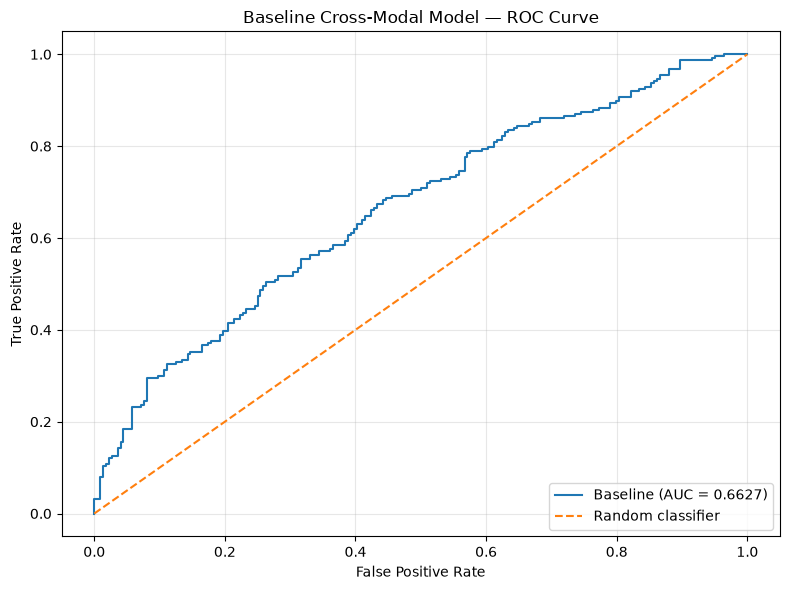


========== ROC CURVE ==========

ROC-AUC: 0.6626674107
Number of ROC points: 204

Figure saved to:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\figures\04_01_baseline_roc_curve.png

ROC curve calculation: PASSED
ROC figure saved: PASSED


In [13]:
# ============================================================
# 04.01 BASELINE CROSS-MODAL EVALUATION
# Cell 10: ROC Curve
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# ------------------------------------------------------------
# Calculate ROC curve
# ------------------------------------------------------------

false_positive_rate, true_positive_rate, roc_thresholds = (
    roc_curve(
        evaluation_labels,
        baseline_probabilities
    )
)

# ------------------------------------------------------------
# Plot ROC curve
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    false_positive_rate,
    true_positive_rate,
    label=f"Baseline (AUC = {baseline_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "Baseline Cross-Modal Model — ROC Curve"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

roc_figure_path = (
    figures_dir
    / "04_01_baseline_roc_curve.png"
)

plt.savefig(
    roc_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

assert len(false_positive_rate) > 1
assert len(true_positive_rate) > 1
assert len(roc_thresholds) > 1

assert roc_figure_path.exists()

print("\n========== ROC CURVE ==========\n")

print(
    "ROC-AUC:",
    f"{baseline_roc_auc:.10f}"
)

print(
    "Number of ROC points:",
    len(false_positive_rate)
)

print("\nFigure saved to:")
print(roc_figure_path)

print("\nROC curve calculation: PASSED")
print("ROC figure saved: PASSED")

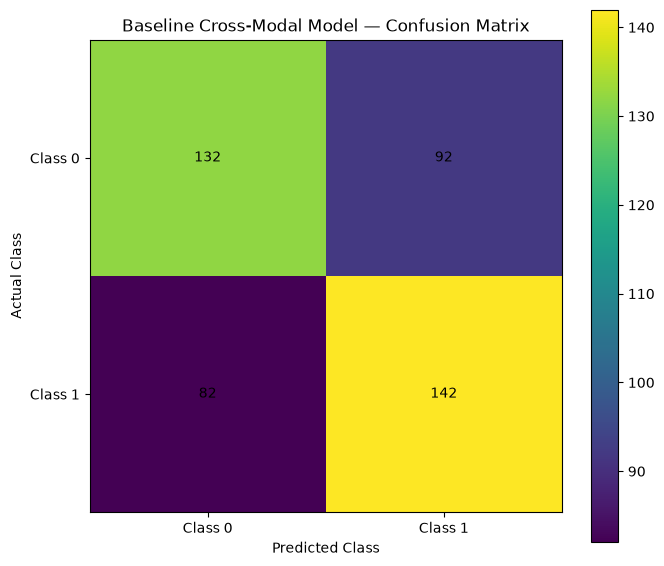

========== CONFUSION MATRIX ==========

True Negative : 132
False Positive: 92
False Negative: 82
True Positive : 142

Total evaluated: 448

Figure saved to:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\figures\04_01_baseline_confusion_matrix.png

Confusion matrix calculation: PASSED
Confusion matrix figure saved: PASSED


In [14]:
# ============================================================
# 04.01 BASELINE CROSS-MODAL EVALUATION
# Cell 11: Confusion Matrix Visualization
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Create confusion matrix figure
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

plt.imshow(
    baseline_confusion_matrix,
    interpolation="nearest"
)

plt.title(
    "Baseline Cross-Modal Model — Confusion Matrix"
)

plt.colorbar()

class_names = [
    "Class 0",
    "Class 1"
]

tick_marks = np.arange(
    len(class_names)
)

plt.xticks(
    tick_marks,
    class_names
)

plt.yticks(
    tick_marks,
    class_names
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

# ------------------------------------------------------------
# Add cell values
# ------------------------------------------------------------

threshold_value = (
    baseline_confusion_matrix.max()
    / 2.0
)

for row in range(
    baseline_confusion_matrix.shape[0]
):

    for column in range(
        baseline_confusion_matrix.shape[1]
    ):

        plt.text(
            column,
            row,
            str(
                baseline_confusion_matrix[
                    row,
                    column
                ]
            ),
            ha="center",
            va="center"
        )

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

confusion_matrix_figure_path = (
    figures_dir
    / "04_01_baseline_confusion_matrix.png"
)

plt.savefig(
    confusion_matrix_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

assert baseline_confusion_matrix.shape == (2, 2)

assert (
    baseline_confusion_matrix.sum()
    == len(evaluation_labels)
)

assert confusion_matrix_figure_path.exists()

print("========== CONFUSION MATRIX ==========\n")

print(
    "True Negative :",
    tn
)

print(
    "False Positive:",
    fp
)

print(
    "False Negative:",
    fn
)

print(
    "True Positive :",
    tp
)

print(
    "\nTotal evaluated:",
    baseline_confusion_matrix.sum()
)

print("\nFigure saved to:")
print(confusion_matrix_figure_path)

print("\nConfusion matrix calculation: PASSED")
print("Confusion matrix figure saved: PASSED")

========== PROBABILITY DISTRIBUTION ==========

Class 0:
  Samples : 224
  Mean    : 0.45505332946777344
  Std     : 0.19943703711032867
  Median  : 0.45475733280181885
  Min     : 0.03269292041659355
  Max     : 0.8974871039390564

Class 1:
  Samples : 224
  Mean    : 0.5757140517234802
  Std     : 0.20390905439853668
  Median  : 0.5970785617828369
  Min     : 0.12415113300085068
  Max     : 0.9379035830497742

Mean probability difference:
  Mean(Class 1) - Mean(Class 0) = 0.12066072225570679


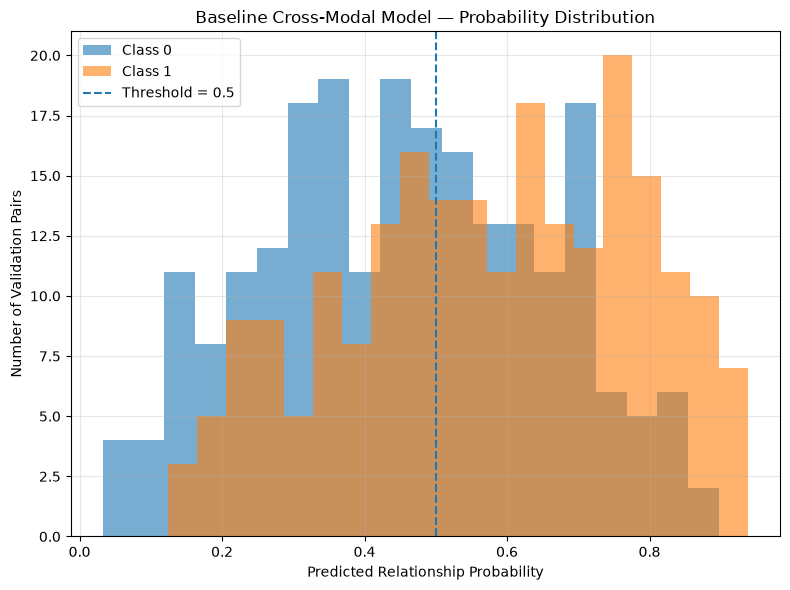


Class 0 distribution check: PASSED
Class 1 distribution check: PASSED
Probability distribution figure saved: PASSED

Probability distribution analysis: COMPLETE


In [15]:
# ============================================================
# 04.01 BASELINE CROSS-MODAL EVALUATION
# Cell 12: Probability Distribution by Class
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Separate probabilities by true class
# ------------------------------------------------------------

class_0_probabilities = (
    baseline_probabilities[
        evaluation_labels == 0
    ]
)

class_1_probabilities = (
    baseline_probabilities[
        evaluation_labels == 1
    ]
)

# ------------------------------------------------------------
# Calculate statistics
# ------------------------------------------------------------

class_0_mean = float(
    np.mean(class_0_probabilities)
)

class_0_std = float(
    np.std(class_0_probabilities)
)

class_0_min = float(
    np.min(class_0_probabilities)
)

class_0_max = float(
    np.max(class_0_probabilities)
)

class_0_median = float(
    np.median(class_0_probabilities)
)

class_1_mean = float(
    np.mean(class_1_probabilities)
)

class_1_std = float(
    np.std(class_1_probabilities)
)

class_1_min = float(
    np.min(class_1_probabilities)
)

class_1_max = float(
    np.max(class_1_probabilities)
)

class_1_median = float(
    np.median(class_1_probabilities)
)

mean_probability_difference = (
    class_1_mean - class_0_mean
)

# ------------------------------------------------------------
# Display statistics
# ------------------------------------------------------------

print("========== PROBABILITY DISTRIBUTION ==========\n")

print("Class 0:")
print("  Samples :", len(class_0_probabilities))
print("  Mean    :", class_0_mean)
print("  Std     :", class_0_std)
print("  Median  :", class_0_median)
print("  Min     :", class_0_min)
print("  Max     :", class_0_max)

print("\nClass 1:")
print("  Samples :", len(class_1_probabilities))
print("  Mean    :", class_1_mean)
print("  Std     :", class_1_std)
print("  Median  :", class_1_median)
print("  Min     :", class_1_min)
print("  Max     :", class_1_max)

print("\nMean probability difference:")
print(
    "  Mean(Class 1) - Mean(Class 0) =",
    mean_probability_difference
)

# ------------------------------------------------------------
# Plot probability distributions
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.hist(
    class_0_probabilities,
    bins=20,
    alpha=0.6,
    label="Class 0"
)

plt.hist(
    class_1_probabilities,
    bins=20,
    alpha=0.6,
    label="Class 1"
)

plt.axvline(
    CLASSIFICATION_THRESHOLD,
    linestyle="--",
    label="Threshold = 0.5"
)

plt.xlabel(
    "Predicted Relationship Probability"
)

plt.ylabel(
    "Number of Validation Pairs"
)

plt.title(
    "Baseline Cross-Modal Model — Probability Distribution"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

probability_distribution_figure_path = (
    figures_dir
    / "04_01_baseline_probability_distribution.png"
)

plt.savefig(
    probability_distribution_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

assert len(class_0_probabilities) == 224
assert len(class_1_probabilities) == 224

assert np.isfinite(
    class_0_probabilities
).all()

assert np.isfinite(
    class_1_probabilities
).all()

assert probability_distribution_figure_path.exists()

print("\nClass 0 distribution check: PASSED")
print("Class 1 distribution check: PASSED")
print("Probability distribution figure saved: PASSED")

print("\nProbability distribution analysis: COMPLETE")

In [16]:
# ============================================================
# 04.01 BASELINE CROSS-MODAL EVALUATION
# Cell 13: Save Probability Analysis Report
# ============================================================

# ------------------------------------------------------------
# Create probability analysis report
# ------------------------------------------------------------

probability_analysis_report = {

    "evaluation": {
        "phase": "04",
        "subphase": "04.01",
        "analysis": "Baseline Probability Distribution",
        "validation_samples": int(
            len(evaluation_labels)
        ),
        "classification_threshold": float(
            CLASSIFICATION_THRESHOLD
        )
    },

    "class_0": {
        "samples": int(
            len(class_0_probabilities)
        ),
        "mean": class_0_mean,
        "std": class_0_std,
        "median": class_0_median,
        "minimum": class_0_min,
        "maximum": class_0_max
    },

    "class_1": {
        "samples": int(
            len(class_1_probabilities)
        ),
        "mean": class_1_mean,
        "std": class_1_std,
        "median": class_1_median,
        "minimum": class_1_min,
        "maximum": class_1_max
    },

    "mean_probability_difference": (
        mean_probability_difference
    ),

    "interpretation": {
        "class_1_mean_higher_than_class_0": bool(
            class_1_mean > class_0_mean
        ),
        "note": (
            "Probabilities represent the predicted cross-modal "
            "pair relationship class defined during Phase 02.08. "
            "They should not be interpreted directly as ASD "
            "diagnostic probabilities."
        )
    },

    "figure": str(
        probability_distribution_figure_path
    )
}

# ------------------------------------------------------------
# Save JSON
# ------------------------------------------------------------

probability_report_path = (
    reports_dir
    / "04_01_baseline_probability_analysis.json"
)

with open(
    probability_report_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        probability_analysis_report,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("========== PROBABILITY ANALYSIS REPORT ==========\n")

print(
    "Class 0 mean probability:",
    f"{class_0_mean:.10f}"
)

print(
    "Class 1 mean probability:",
    f"{class_1_mean:.10f}"
)

print(
    "Mean probability difference:",
    f"{mean_probability_difference:.10f}"
)

print("\nReport saved to:")
print(probability_report_path)

print("\nFigure:")
print(probability_distribution_figure_path)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

assert probability_report_path.exists()

with open(
    probability_report_path,
    "r",
    encoding="utf-8"
) as f:

    saved_probability_report = json.load(f)

assert (
    saved_probability_report["class_0"]["samples"]
    == 224
)

assert (
    saved_probability_report["class_1"]["samples"]
    == 224
)

assert np.isclose(
    saved_probability_report[
        "mean_probability_difference"
    ],
    mean_probability_difference
)

print("\nProbability report verification: PASSED")
print("Probability analysis artifact: SAVED")

========== PROBABILITY ANALYSIS REPORT ==========

Class 0 mean probability: 0.4550533295
Class 1 mean probability: 0.5757140517
Mean probability difference: 0.1206607223

Report saved to:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports\04_01_baseline_probability_analysis.json

Figure:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\figures\04_01_baseline_probability_distribution.png

Probability report verification: PASSED
Probability analysis artifact: SAVED


In [18]:
# ============================================================
# 04.01 BASELINE CROSS-MODAL EVALUATION
# Cell 14: Corrected Validation Pair-Type Composition Audit
# ============================================================

print("========== PAIR-TYPE COMPOSITION AUDIT ==========\n")

# ------------------------------------------------------------
# Display metadata columns
# ------------------------------------------------------------

print("Metadata columns:")
print(
    validation_metadata.columns.tolist()
)

# ------------------------------------------------------------
# Required columns
# ------------------------------------------------------------

required_columns = [
    "source_modality",
    "target_modality",
    "source_index",
    "target_index",
    "source_class",
    "target_class",
    "pair_label",
    "pair_type"
]

for column in required_columns:
    assert column in validation_metadata.columns

# ------------------------------------------------------------
# Verify metadata row count
# ------------------------------------------------------------

assert len(validation_metadata) == 448

# ------------------------------------------------------------
# Inspect actual pair_type column
# ------------------------------------------------------------

pair_type_counts = (
    validation_metadata["pair_type"]
    .value_counts()
    .sort_index()
)

print("\nExisting pair_type column:")

for pair_type, count in pair_type_counts.items():

    print(
        f"  {pair_type}: {count}"
    )

# ------------------------------------------------------------
# Verify pair_type corresponds to pair_label
# ------------------------------------------------------------

negative_type_labels = validation_metadata.loc[
    validation_metadata["pair_type"] == "negative",
    "pair_label"
].unique()

positive_type_labels = validation_metadata.loc[
    validation_metadata["pair_type"] == "positive",
    "pair_label"
].unique()

print("\nPair-type / label relationship:")

print(
    "  Negative pair labels:",
    negative_type_labels
)

print(
    "  Positive pair labels:",
    positive_type_labels
)

assert set(
    negative_type_labels
).issubset({0})

assert set(
    positive_type_labels
).issubset({1})

# ------------------------------------------------------------
# Construct modality combination
# ------------------------------------------------------------

validation_metadata[
    "modality_combination"
] = (
    validation_metadata["source_modality"]
    + "-"
    + validation_metadata["target_modality"]
)

# ------------------------------------------------------------
# Modality combination counts
# ------------------------------------------------------------

modality_combination_counts = (
    validation_metadata[
        "modality_combination"
    ]
    .value_counts()
    .sort_index()
)

print("\nModality combinations:")

for combination, count in (
    modality_combination_counts.items()
):

    print(
        f"  {combination}: {count}"
    )

# ------------------------------------------------------------
# Modality combination × pair label
# ------------------------------------------------------------

modality_label_counts = (
    validation_metadata
    .groupby(
        [
            "modality_combination",
            "pair_label"
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
)

print("\nModality combination × pair label:")
print(
    modality_label_counts
)

# ------------------------------------------------------------
# Verify total number of pairs
# ------------------------------------------------------------

assert (
    modality_combination_counts.sum()
    == 448
)

# ------------------------------------------------------------
# Expected modality combinations
# ------------------------------------------------------------

expected_combinations = {
    "Genetic-Behavioral",
    "Genetic-Environmental",
    "Behavioral-Environmental"
}

actual_combinations = set(
    modality_combination_counts.index
)

print("\nExpected modality combinations:")
print(
    expected_combinations
)

print("\nActual modality combinations:")
print(
    actual_combinations
)

assert actual_combinations == expected_combinations

# ------------------------------------------------------------
# Verify expected counts from Phase 02.08
# ------------------------------------------------------------

expected_counts = {
    "Genetic-Behavioral": 48,
    "Genetic-Environmental": 48,
    "Behavioral-Environmental": 352
}

for combination, expected_count in (
    expected_counts.items()
):

    actual_count = int(
        modality_combination_counts[
            combination
        ]
    )

    print(
        f"\n{combination}:"
    )

    print(
        "  Actual count  :",
        actual_count
    )

    print(
        "  Expected count:",
        expected_count
    )

    assert actual_count == expected_count

# ------------------------------------------------------------
# Verify class balance within each modality combination
# ------------------------------------------------------------

for combination in expected_combinations:

    subset = validation_metadata[
        validation_metadata[
            "modality_combination"
        ] == combination
    ]

    class_counts = (
        subset["pair_label"]
        .value_counts()
    )

    class_0 = int(
        class_counts.get(0, 0)
    )

    class_1 = int(
        class_counts.get(1, 0)
    )

    print(
        f"\n{combination} label counts:"
    )

    print(
        "  Class 0:",
        class_0
    )

    print(
        "  Class 1:",
        class_1
    )

    assert class_0 == class_1

# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------

print("\nModality combination count verification: PASSED")
print("Modality combination label-balance verification: PASSED")
print("Pair-type metadata verification: PASSED")

print("\nCorrected validation pair composition audit: PASSED")

========== PAIR-TYPE COMPOSITION AUDIT ==========

Metadata columns:
['source_modality', 'target_modality', 'source_index', 'target_index', 'source_class', 'target_class', 'pair_label', 'pair_type']

Existing pair_type column:
  negative: 224
  positive: 224

Pair-type / label relationship:
  Negative pair labels: [0]
  Positive pair labels: [1]

Modality combinations:
  Behavioral-Environmental: 352
  Genetic-Behavioral: 48
  Genetic-Environmental: 48

Modality combination × pair label:
pair_label                  0    1
modality_combination              
Behavioral-Environmental  176  176
Genetic-Behavioral         24   24
Genetic-Environmental      24   24

Expected modality combinations:
{'Genetic-Behavioral', 'Genetic-Environmental', 'Behavioral-Environmental'}

Actual modality combinations:
{'Genetic-Behavioral', 'Genetic-Environmental', 'Behavioral-Environmental'}

Genetic-Behavioral:
  Actual count  : 48
  Expected count: 48

Genetic-Environmental:
  Actual count  : 48
  Expect

In [19]:
# ============================================================
# 04.01 BASELINE CROSS-MODAL EVALUATION
# Cell 15: Save Validation Pair Composition Report
# ============================================================

# ------------------------------------------------------------
# Build composition report
# ------------------------------------------------------------

pair_composition_report = {
    "evaluation": {
        "phase": "04",
        "subphase": "04.01",
        "analysis": "Validation Pair Composition",
        "total_validation_pairs": 448
    },

    "pair_type": {
        "negative": int(
            pair_type_counts["negative"]
        ),
        "positive": int(
            pair_type_counts["positive"]
        )
    },

    "modality_combinations": {
        combination: int(
            modality_combination_counts[
                combination
            ]
        )
        for combination in sorted(
            expected_combinations
        )
    },

    "modality_combination_class_counts": {
        combination: {
            "class_0": int(
                modality_label_counts.loc[
                    combination,
                    0
                ]
            ),
            "class_1": int(
                modality_label_counts.loc[
                    combination,
                    1
                ]
            )
        }
        for combination in sorted(
            expected_combinations
        )
    },

    "verification": {
        "total_pairs_verified": True,
        "expected_modality_combinations_verified": True,
        "label_balance_verified": True
    }
}

# ------------------------------------------------------------
# Save JSON
# ------------------------------------------------------------

pair_composition_report_path = (
    reports_dir
    / "04_01_validation_pair_composition.json"
)

with open(
    pair_composition_report_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        pair_composition_report,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("========== PAIR COMPOSITION REPORT ==========\n")

print(
    "Total validation pairs:",
    pair_composition_report[
        "evaluation"
    ][
        "total_validation_pairs"
    ]
)

print("\nPair types:")

for pair_type, count in (
    pair_composition_report[
        "pair_type"
    ].items()
):

    print(
        f"  {pair_type}: {count}"
    )

print("\nModality combinations:")

for combination, count in (
    pair_composition_report[
        "modality_combinations"
    ].items()
):

    print(
        f"  {combination}: {count}"
    )

print("\nReport saved to:")
print(pair_composition_report_path)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

assert pair_composition_report_path.exists()

with open(
    pair_composition_report_path,
    "r",
    encoding="utf-8"
) as f:

    saved_composition_report = json.load(f)

assert (
    saved_composition_report[
        "evaluation"
    ][
        "total_validation_pairs"
    ]
    == 448
)

assert (
    sum(
        saved_composition_report[
            "modality_combinations"
        ].values()
    )
    == 448
)

assert (
    saved_composition_report[
        "verification"
    ][
        "label_balance_verified"
    ]
    is True
)

print("\nReport verification: PASSED")
print("Pair composition artifact: SAVED")
print("\n04.01 composition documentation: COMPLETE")

========== PAIR COMPOSITION REPORT ==========

Total validation pairs: 448

Pair types:
  negative: 224
  positive: 224

Modality combinations:
  Behavioral-Environmental: 352
  Genetic-Behavioral: 48
  Genetic-Environmental: 48

Report saved to:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports\04_01_validation_pair_composition.json

Report verification: PASSED
Pair composition artifact: SAVED

04.01 composition documentation: COMPLETE
